<a href="https://colab.research.google.com/github/Renyambar/Reny_MachineLearning/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Praktikum Klasterisasi Customer Credit Card

##Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

##Membaca dan memeriksa dataset

In [2]:
df = pd.read_csv("CC_Customer_Dataset.csv")

print("Ukuran dataset:", df.shape)
display(df.head())
print("\nInformasi kolom:")
df.info()
print("\nJumlah missing value per kolom:")
display(df.isnull().sum())

Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3



Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Jumlah missing value per kolom:


,0
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


##Soal 1 — Scatterplot dan hubungan linier

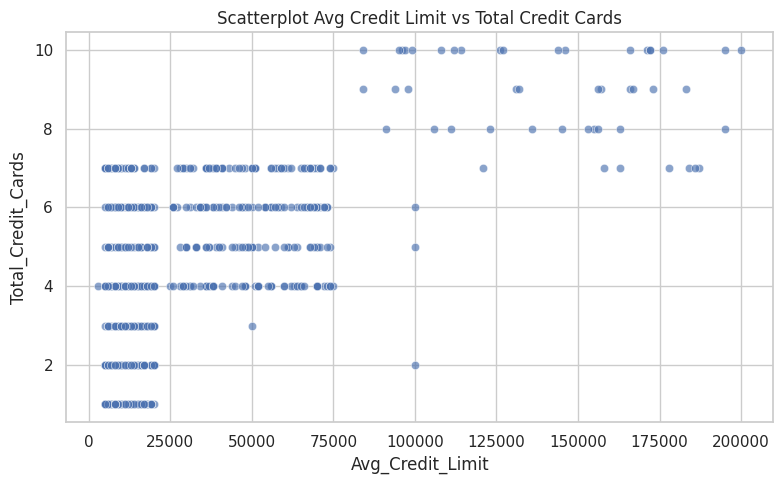

Korelasi Pearson: 0.6089
Interpretasi: terdapat hubungan linier sedang, tetapi sebaran masih cukup lebar.
Periksa scatterplot juga: korelasi mengukur hubungan linier, bukan apakah semua titik tepat berada pada satu garis.


In [3]:
x_col = "Avg_Credit_Limit"
y_col = "Total_Credit_Cards"

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=x_col, y=y_col, alpha=0.65)
plt.title("Scatterplot Avg Credit Limit vs Total Credit Cards")
plt.xlabel("Avg_Credit_Limit")
plt.ylabel("Total_Credit_Cards")
plt.tight_layout()
plt.show()

corr = df[[x_col, y_col]].corr(method="pearson").iloc[0, 1]
print(f"Korelasi Pearson: {corr:.4f}")

if abs(corr) < 0.3:
    print("Interpretasi: hubungan linier cenderung lemah; titik tidak membentuk pola garis yang jelas.")
elif abs(corr) < 0.7:
    print("Interpretasi: terdapat hubungan linier sedang, tetapi sebaran masih cukup lebar.")
else:
    print("Interpretasi: terdapat hubungan linier relatif kuat.")
print("Periksa scatterplot juga: korelasi mengukur hubungan linier, bukan apakah semua titik tepat berada pada satu garis.")

##Soal 2 — K-Means dan elbow method

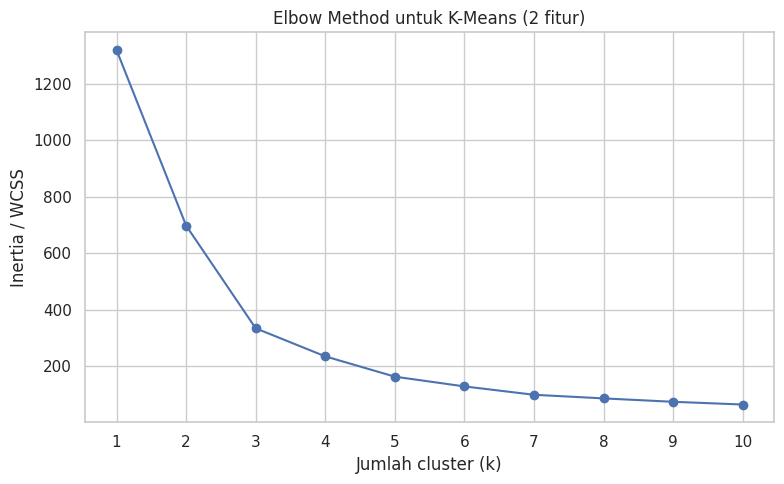

In [4]:
# K-Means untuk visualisasi soal menggunakan dua fitur yang diminta.
features_2d = df[[x_col, y_col]].copy()
scaler_2d = StandardScaler()
X_2d = scaler_2d.fit_transform(features_2d)

inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_2d)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.title("Elbow Method untuk K-Means (2 fitur)")
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia / WCSS")
plt.tight_layout()
plt.show()

In [5]:
best_k = 3

kmeans_2d = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["KMeans_Cluster_2Fitur"] = kmeans_2d.fit_predict(X_2d)

print(f"Jumlah cluster K-Means yang dipilih: k={best_k}")
print(df["KMeans_Cluster_2Fitur"].value_counts().sort_index())

Jumlah cluster K-Means yang dipilih: k=3
KMeans_Cluster_2Fitur
0    330
1     48
2    282
Name: count, dtype: int64


##Soal 3 — Scatterplot hasil K-Means

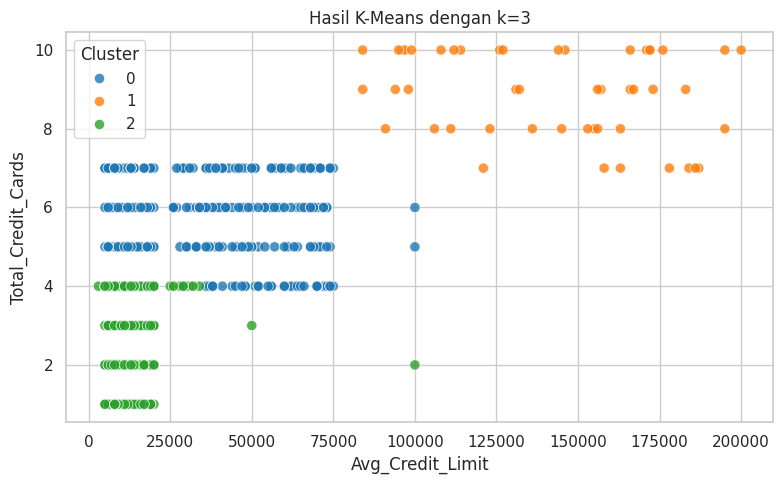

In [6]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x=x_col,
    y=y_col,
    hue="KMeans_Cluster_2Fitur",
    palette="tab10",
    s=55,
    alpha=0.8
)
plt.title(f"Hasil K-Means dengan k={best_k}")
plt.xlabel("Avg_Credit_Limit")
plt.ylabel("Total_Credit_Cards")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

##Soal 4 — DBSCAN dengan seluruh variabel yang dapat digunakan

In [7]:
feature_cols = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made"
]

X_all_df = df[feature_cols].copy()
X_all_df = X_all_df.fillna(X_all_df.median(numeric_only=True))

scaler_all = StandardScaler()
X_all = scaler_all.fit_transform(X_all_df)

print("Fitur DBSCAN:", feature_cols)
print("Bentuk matriks fitur:", X_all.shape)

Fitur DBSCAN: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Bentuk matriks fitur: (660, 5)


##Soal 5 — Menentukan eps DBSCAN dengan k-distance plot

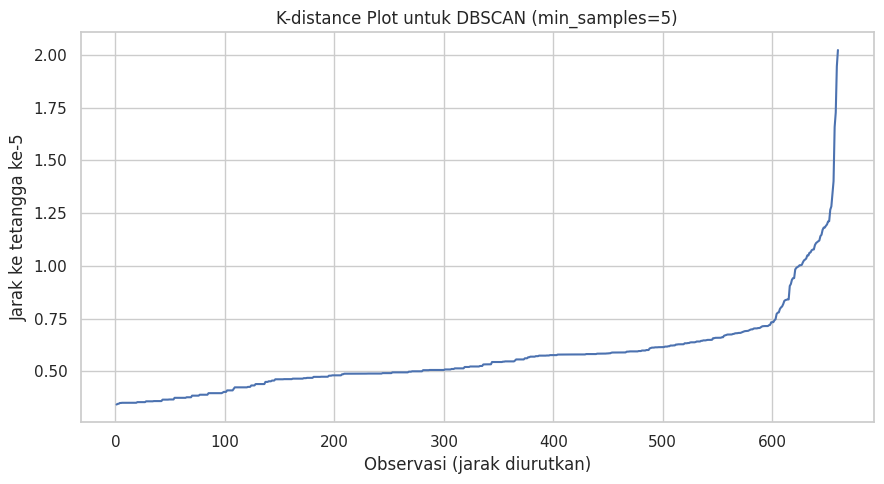

In [8]:
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_all)
distances, indices = neighbors_fit.kneighbors(X_all)

# Jarak ke tetangga ke-min_samples, diurutkan dari kecil ke besar
k_distances = np.sort(distances[:, min_samples - 1])

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(k_distances) + 1), k_distances)
plt.title(f"K-distance Plot untuk DBSCAN (min_samples={min_samples})")
plt.xlabel("Observasi (jarak diurutkan)")
plt.ylabel(f"Jarak ke tetangga ke-{min_samples}")
plt.tight_layout()
plt.show()

In [9]:
eps_value = 0.8

dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_all)
df["DBSCAN_Cluster"] = dbscan_labels

n_clusters = len(set(dbscan_labels) - {-1})
n_noise = int(np.sum(dbscan_labels == -1))

print(f"Parameter eps       : {eps_value}")
print(f"Parameter min_samples: {min_samples}")
print(f"Jumlah cluster (tanpa noise): {n_clusters}")
print(f"Jumlah noise         : {n_noise} dari {len(dbscan_labels)} data")
print("\nJumlah data per label (-1 berarti noise):")
print(df["DBSCAN_Cluster"].value_counts().sort_index())

Parameter eps       : 0.8
Parameter min_samples: 5
Jumlah cluster (tanpa noise): 2
Jumlah noise         : 44 dari 660 data

Jumlah data per label (-1 berarti noise):
DBSCAN_Cluster
-1     44
 0    606
 1     10
Name: count, dtype: int64


##Soal 6 — Silhouette Score dan Davies–Bouldin Index (DBI) untuk DBSCAN

In [10]:
mask_core = df["DBSCAN_Cluster"].to_numpy() != -1
X_eval = X_all[mask_core]
labels_eval = df.loc[mask_core, "DBSCAN_Cluster"].to_numpy()
unique_clusters = np.unique(labels_eval)

print("Jumlah data non-noise:", len(labels_eval))
print("Label cluster non-noise:", unique_clusters)

if len(unique_clusters) >= 2 and len(labels_eval) > len(unique_clusters):
    sil = silhouette_score(X_eval, labels_eval)
    dbi = davies_bouldin_score(X_eval, labels_eval)
    print(f"Silhouette Score (non-noise): {sil:.4f}")
    print(f"Davies-Bouldin Index / DBI (non-noise): {dbi:.4f}")
    print("Interpretasi: silhouette lebih tinggi umumnya lebih baik; DBI lebih rendah umumnya lebih baik.")
else:
    print("Silhouette Score dan DBI tidak dapat dihitung secara valid karena jumlah cluster non-noise kurang dari 2 atau data tidak mencukupi.")
    print("Coba sesuaikan eps dan/atau min_samples berdasarkan k-distance plot, lalu jalankan ulang sel DBSCAN dan sel evaluasi ini.")

Jumlah data non-noise: 616
Label cluster non-noise: [0 1]
Silhouette Score (non-noise): 0.5445
Davies-Bouldin Index / DBI (non-noise): 0.5154
Interpretasi: silhouette lebih tinggi umumnya lebih baik; DBI lebih rendah umumnya lebih baik.
